# Saturn on mouse brain MERFISH: RNA and isoform usage

This tutorial runs the Saturn workflow on RT&T-MERFISH data from a coronal section of the adult mouse brain (sample 5 of
the `ISO` file set, cell-by-feature matrix `cellxgene_ISO_labels.h5ad`). The panel reads about 23,000 genes and about
10,000 isoforms in the same cells. We pool 47,649 cells into 2,721 bins of 100 um. This is the fit behind Fig. 4 of the
Saturn manuscript.

Each modality has its own isodepth: `rho_RNA` orders the bins by gene expression and `rho_Isoform` orders them by isoform
usage, which is the share of a gene's reads carried by each isoform and does not depend on the gene's expression level.

We are going to build the two targets, fit Saturn with the published settings and check that the result is the published
fit, call and annotate domains on each axis, fit isoform usage along its axis with a binomial model, find the isoforms that
switch between domains, follow one cell type across the boundary, and ask what the cross pathways explain.

The notebook ran in 9 to 21 min on a shared machine, most of it the fit, which took between 1 and 12 min depending on the load. Every
published table that exists is compared with the result in a visible cell.

## Data preprocessing

Let's load the packages and fix the thread settings first. A CPU fit depends on the thread count as well as on the seed, and
the published fit used 8 torch threads with `OMP_NUM_THREADS` unset, so this has to happen before torch is imported.

In [1]:
import json
import os
os.environ.pop("OMP_NUM_THREADS", None)
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.optimize import minimize
from scipy.spatial import cKDTree
from scipy.stats import chi2, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from statsmodels.stats.multitest import multipletests

import saturn
from saturn import crossterm as CT, piecewise as pw
from saturn.theme import MODALITY, REGION, ANCHOR
saturn.theme.set_theme(8)                      # the colours and fonts of the paper figures

WORK = Path(os.environ.get("SATURN_WORKSPACE", "saturn_workspace"))   # the workspace folder: inputs, and published results in published/
PUB = WORK / "published"                                          # published targets and tables, used only for comparison
DS = "rtt_merfish_s5_iso100_sv_pca_shrunk"
FIT = PUB / f"{DS}_norestart_lc0.3"
published = np.load(PUB / f"targets_{DS}.npz", allow_pickle=True)


def maxdiff(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return float(np.nanmax(np.abs(a - b)))

Features whose names start with `ENSMUST` are isoforms, and the others are genes. A transcript-to-gene table gives each isoform
its gene.

In [2]:
a = ad.read_h5ad(WORK / "cellxgene_ISO_labels.h5ad")
a = a[a.obs["sample"].astype(str) == "5"].copy()

is_iso = np.array([v.startswith("ENSMUST") for v in a.var_names])
tx2gene = pd.read_csv(WORK / "ensembl_tx2gene_mm.tsv", sep="\t").drop_duplicates("tx").set_index("tx")["gene"]
iso_gene = tx2gene.reindex(a.var_names[is_iso]).values
mapped = pd.notna(iso_gene)

X = sp.csr_matrix(a.X)
X_gene = X[:, np.where(~is_iso)[0]]
X_iso = X[:, np.where(is_iso)[0][mapped]].tocsc()
genes = np.array(a.var_names[~is_iso], str)
iso_gene = np.array(iso_gene[mapped], str)
iso_name = np.array([v.split(".")[0] for v in a.var_names[is_iso][mapped]])
cell_xy = a.obs[["global_x", "global_y"]].values.astype(float)
cell_type = a.obs["cell_label"].astype(str).values
print("cells", a.n_obs, " genes", X_gene.shape[1], " isoforms with a gene", X_iso.shape[1])

cells 47649  genes 22930  isoforms with a gene 9749


A single cell holds too few reads per isoform, so cells are pooled in 100 um bins, and bins with fewer than 5 cells are dropped.
`G` maps cells to bins and `cell_bin` keeps the bin of every cell, because the switch analysis later goes back to single cells.

In [3]:
key = np.floor(cell_xy / 100.0).astype(np.int64)
code = key[:, 0] * 1_000_000 + key[:, 1]
uniq, inv, n_cells = np.unique(code, return_inverse=True, return_counts=True)
kept = np.where(n_cells >= 5)[0]
G = sp.csr_matrix((np.ones(len(inv)), (inv, np.arange(len(inv)))), shape=(len(uniq), len(inv)))[kept]
bin_of_uniq = np.full(len(uniq), -1)
bin_of_uniq[kept] = np.arange(len(kept))
cell_bin = bin_of_uniq[inv]

counts_R = sp.csr_matrix(G @ X_gene)
counts_I = sp.csc_matrix(G @ X_iso).astype(float)
coords = np.asarray(G @ cell_xy) / n_cells[kept][:, None]
barcodes = uniq[kept].astype(str)
lib_R = np.asarray(counts_R.sum(1)).ravel().clip(1)
depth_I = np.asarray(counts_I.sum(1)).ravel()
coords_z = saturn.zscore_coords(coords)

print("bins", len(coords), " median cells per bin", np.median(n_cells[kept]), " share of cells in bins", round((cell_bin >= 0).mean(), 3))
print("same bins as the published targets:", (barcodes == published["barcodes"].astype(str)).all(),
      " max|diff| coords", maxdiff(coords, published["coords"]), " coords_z", maxdiff(coords_z, published["coords_z"]),
      " depth_Isoform", maxdiff(depth_I, published["depth_Isoform"]))

bins 2721  median cells per bin 17.0  share of cells in bins 0.992
same bins as the published targets: True  max|diff| coords 0.0  coords_z 0.0  depth_Isoform 0.0


### Isoform target

Isoforms enter the target only for genes whose usage varies in space. This selection comes from SPLISOSM (`SplisosmNP`, HSIC-IR
test, BH-adjusted p < 0.05) run on these bins, which needs its own package and is run once by
`scripts/rtt_isoform_multinomial.py`, so here we read its saved table. Within a selected gene we keep the isoforms with at
least 5% of the gene's reads, major isoform first.

In [4]:
sv_table = pd.read_csv(PUB / "rtt_isoform_variants/whole_sv/sv_results.csv", index_col=0)
sv_genes = set(sv_table.index[sv_table.ir_padj < 0.05])
tot = np.asarray(counts_I.sum(0)).ravel()

blocks = {}
for g, idx in pd.Series(np.arange(len(iso_gene))).groupby(iso_gene):
    if g in sv_genes:
        idx = idx.values
        idx = idx[tot[idx] / tot[idx].sum() >= 0.05]
        blocks[g] = idx[np.argsort(-tot[idx])]
cols = np.concatenate(list(blocks.values()))
print(len(sv_table), "genes tested;", len(blocks), "with spatially variable usage;", len(cols), "isoforms")
sv_table.head(3)

3244 genes tested; 1071 with spatially variable usage; 2629 isoforms


,n_iso,reads,ir_stat,ir_padj,gc_padj
Lamp5,2,12887.0,0.000723,2.107243e-234,6.565181e-293
Tcf7l2,2,6582.0,0.000707,1.169110e-233,0.000000e+00
Mef2c,3,13485.0,0.000559,4.462047e-199,0.000000e+00


`saturn.isoform_usage_pca` is the general function for isoform counts. Per bin it shrinks each isoform's usage toward the
gene's section-wide usage with `alpha` pseudo-reads, takes the centred log-ratio within each gene, and runs a PCA over isoforms.
`depth` regresses out log depth, and `n_top` limits the PCA to the most variable isoforms. Use this on a new dataset.

The published target is a close variant of it. It also weights each gene by `1 / sqrt(J - 1)`, where `J` is the number of
isoforms of the gene, so that genes with many isoforms do not count more, and it does not regress depth. The function has no
option for this weight, so the components below follow the published ones but do not equal them.

In [5]:
Y_api, info = saturn.isoform_usage_pca(counts_I[:, cols], iso_gene[cols], K=10, alpha=2, min_gene_reads=0, n_top=len(cols))
r_api = np.abs(np.corrcoef(Y_api.T, published["Y_Isoform"].T)[:10, 10:])
print("isoform_usage_pca, best |r| of each component to a published component:", r_api.max(1).round(3).tolist())
print(info["n_genes"], "genes,", info["n_isoforms"], "isoforms; max|diff| to the published target", round(maxdiff(Y_api, published["Y_Isoform"]), 3))

isoform_usage_pca, best |r| of each component to a published component: [0.987, 0.972, 0.968, 0.953, 0.965, 0.649, 0.239, 0.137, 0.323, 0.302]
1071 genes, 2629 isoforms; max|diff| to the published target 13.157


So we write the published recipe out: 2 pseudo-reads, log-ratio within gene, gene weight, then PCA with 10 components and
`saturn.scale_target`, which applies one scale per modality so that the mean column variance is 1. This rebuilds the target
of the paper from the raw counts.

In [6]:
Z = []
for g, idx in blocks.items():
    C = counts_I[:, idx].toarray()
    N = C.sum(1, keepdims=True)
    P = (C + 2 * C.sum(0) / C.sum()) / (N + 2)
    Z.append((np.log(P) - np.log(P).mean(1, keepdims=True)) / np.sqrt(len(idx) - 1))
Z = np.hstack(Z)
Z -= Z.mean(0)
U, s, _ = np.linalg.svd(Z, full_matrices=False)
Y_I = saturn.scale_target(U[:, :10] * s[:10], "global").astype(np.float32)
print("input", Z.shape, " max|diff| to the published target", maxdiff(Y_I, published["Y_Isoform"]))

input (2721, 2629)  max|diff| to the published target 0.0


### RNA target

`saturn.rna_glmpc_real` runs Poisson GLM-PCA (Townes et al.) over 3,000 Pearson-residual variable genes. It starts from an
unseeded `np.random` state, so each call gives a slightly different target, and the fit depends on the draw. We run it once to
show the call, print how well each component matches the published one, and then load the paper's `Y_RNA` from the targets file,
so that everything below matches the manuscript. Draws can also differ in the penalty GLM-PCA needs to converge, which the call prints.

In [7]:
Y_draw, info_R = saturn.rna_glmpc_real(counts_R, K=10)
r_draw = np.abs(np.corrcoef(Y_draw.T, published["Y_RNA"].T)[:10, 10:])
print(info_R["method"], " this draw, best |r| of each component to a published component:", r_draw.max(1).round(3).tolist())
print("max|diff| to the published target", round(maxdiff(Y_draw, published["Y_RNA"]), 3))

Y_R = np.asarray(published["Y_RNA"], np.float32)
depth_R = info_R["depth"]                                  # reads over the genes GLM-PCA keeps (detected in >= 1% of bins)
print("max|diff| depth_RNA to the targets file", maxdiff(depth_R, published["depth_RNA"]))

      glmpca converged with penalty=1


glmpca  this draw, best |r| of each component to a published component: [0.83, 0.639, 0.714, 0.717, 0.703, 0.769, 0.5, 0.733, 0.593, 0.478]
max|diff| to the published target 8.961
max|diff| depth_RNA to the targets file 0.0


`check_target` reports how strongly each leading component follows depth (`depth_corr`), how much of the variance it holds
(`var_share`) and whether it is spatially structured (`moran`).

In [8]:
targets, modalities = [Y_R, Y_I], ["RNA", "Isoform"]
print(saturn.check_target(Y_R, depth=depth_R, coords=coords))
print(saturn.check_target(Y_I, depth=depth_I, coords=coords))

{'var_share': [0.168, 0.1283, 0.1281, 0.1205, 0.1135, 0.1067, 0.0633, 0.0617, 0.0585, 0.0516], 'elbow': None, 'depth_corr': [0.516, 0.196, 0.286, 0.674, 0.369], 'depth_leak': 0.674, 'moran': 0.721}
{'var_share': [0.2795, 0.1457, 0.1092, 0.1046, 0.0908, 0.062, 0.0548, 0.052, 0.051, 0.0504], 'elbow': None, 'depth_corr': [0.715, 0.356, 0.008, 0.138, 0.52], 'depth_leak': 0.715, 'moran': 0.694}


Some leading components follow depth (`depth_leak` 0.674 for RNA and 0.715 for isoforms), above the value of about 0.3 that the
function's documentation asks for. Read depth differs between brain regions here, as the domain table below shows, so these components
are not depth alone. The published targets keep them, and we check the fitted axes against depth after the fit.

## Fitting Saturn

`saturn.fit` trains the model and passes extra keywords to `train_saturn`. The defaults of `train_saturn` are the settings of
most published fits. This fit changes three of them, because with the defaults `rho_Isoform` collapsed onto `rho_RNA`:

- `n_restarts=0`: no restarts of a head. They were accepted on held-out gains of 1 to 2% and left a fresh, near-planar head.
- `lam_cross=0.3`: the cross pathways pay 10 times more, so the RNA axis does not absorb the isoform target.
- `refit_all_epochs=0`: `saturn.fit` otherwise adds a refit of 3,000 epochs. Without restarts no spots are held out, so the
  model already trains on every bin.

Seed 42 with `threads=8`.

In [9]:
res = saturn.fit(targets, coords_z, modalities, seeds=[42], threads=8, refit_all_epochs=0, n_restarts=0, lam_cross=0.3,
                 depth=dict(RNA=depth_R, Isoform=depth_I))
print("best seed", res.best_seed, " whole-section fit", round(res.fit_all_by_seed[0], 4))

best seed 42  whole-section fit 0.9369


## Comparing with the published fit

We read the published axes and the fit diagnostics and compare them per axis. A difference near 1e-15 is the rounding of the saved
CSV, so the fit is the published fit.

In [10]:
pub_axes = pd.read_csv(FIT / "axes.csv", index_col=0)
pub_axes.index = pub_axes.index.astype(str)
assert list(pub_axes.index) == list(barcodes)
for k, m in enumerate(modalities):
    print(f"rho_{m}: max|diff| {maxdiff(res.axes[:, k], pub_axes[f'd_{m}']):.3g}, |r| {abs(np.corrcoef(res.axes[:, k], pub_axes[f'd_{m}'])[0, 1]):.6f}")
diag = json.load(open(FIT / "diag.json"))
print("whole-section fit", round(res.fit_all_by_seed[0], 6), " published", round(diag["fit_all"], 6))

rho_RNA: max|diff| 1.78e-15, |r| 1.000000
rho_Isoform: max|diff| 8.88e-16, |r| 1.000000
whole-section fit 0.936943  published 0.936943


## Checking the fit

Before any biology, look at the variance explained (`r2`), the cross-pathway share (`coupling`), the correlation of each axis with
depth and the correlation between the axes. Entry `[m, k]` of the coupling matrix is the share of the predicted variance of
modality `m` carried by axis `k`. It is a variance share, not a causal arrow. The coupling is not identifiable when the axes
correlate above about 0.8.

In [11]:
print(pd.DataFrame(res.r2).T.round(3))
print("published\n", pd.DataFrame(diag["R2_whole"]).T.round(3))
print("\ncoupling (row = modality, column = axis)\n", pd.DataFrame(res.coupling, modalities, modalities).round(3))
print("published", diag["coupling"])
print("\naxis vs depth, |Spearman|", {k: round(v, 3) for k, v in res.axis_depth_corr.items()})
print("axis vs axis, Spearman", res.axis_axis_corr[0][1])

          full  own_axis_only  other_axes_only
RNA      0.577          0.488            0.150
Isoform  0.486          0.457            0.067
published
           full  own_axis_only  other_axes_only
RNA      0.577          0.488            0.150
Isoform  0.486          0.457            0.067

coupling (row = modality, column = axis)
            RNA  Isoform
RNA      0.908    0.092
Isoform  0.030    0.970
published [[0.908, 0.092], [0.03, 0.97]]

axis vs depth, |Spearman| {'RNA': 0.062, 'Isoform': 0.196}
axis vs axis, Spearman 0.92


The two axes correlate at 0.92, above that limit, so the coupling values of this fit should not be read as separate shares. The axes
follow depth weakly (0.062 and 0.196).

The sign of an isodepth is arbitrary, so `orient` aligns it with a reference before comparing or plotting. The published axes
run from subcortical regions to the cortex, and the excitatory marker `Slc17a7` gives the same direction on a new dataset. It is
saved in the targets file as `mk_Slc17a7`.

flipped relative to the fit: [False, False]


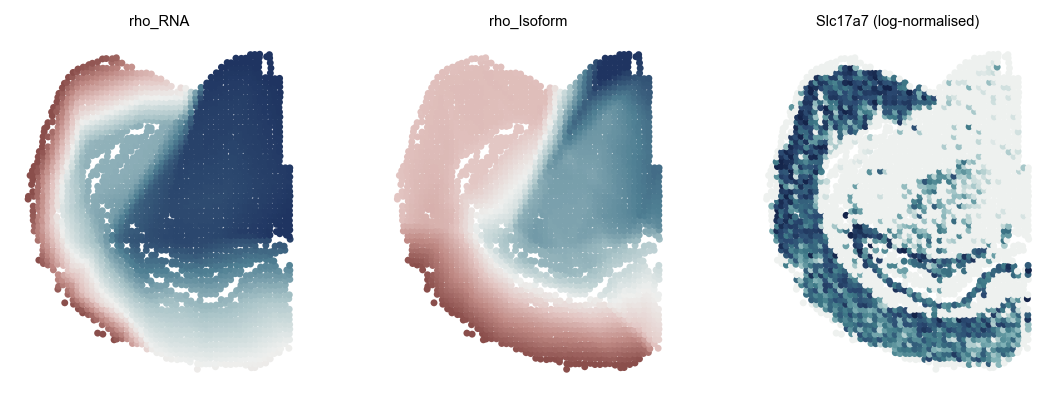

In [12]:
axes = saturn.orient(res.axes, np.c_[published["mk_Slc17a7"], published["mk_Slc17a7"]])
print("flipped relative to the fit:", (np.sign(axes[0]) != np.sign(res.axes[0])).tolist())
d_R, d_I = axes[:, 0], axes[:, 1]

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
saturn.plotting.spatial(ax[0], coords, d_R, "rho_RNA")
saturn.plotting.spatial(ax[1], coords, d_I, "rho_Isoform")
saturn.plotting.spatial(ax[2], coords, published["mk_Slc17a7"], "Slc17a7 (log-normalised)", cmap="saturn_seq_r")
plt.show()

## Domains along each axis

Each modality is segmented on its own axis with its own targets. `saturn.domains.choose_k` takes the elbow of the error curve
of GASTON's dynamic programme, `gaston_domains` assigns the bins (0 = low end of the axis) and `boundaries` returns the contour
levels for maps. The elbow gives K = 4 on `rho_RNA` and K = 3 on `rho_Isoform`.

K, RNA axis 4 [748, 547, 377, 1049]  published [748, 547, 377, 1049]
K, isoform axis 3 [1560, 568, 593]  published [1560, 568, 593]


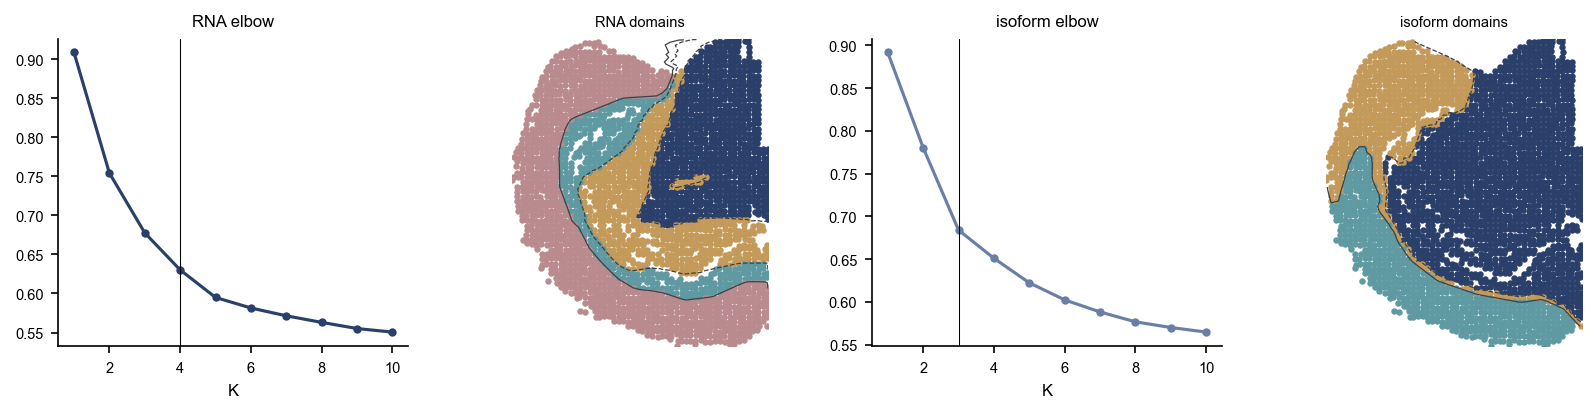

In [13]:
k_R, curve_R = saturn.domains.choose_k(d_R, Y_R)
k_I, curve_I = saturn.domains.choose_k(d_I, Y_I)
lab_R = saturn.domains.gaston_domains(d_R, Y_R, n_domains=k_R)
lab_I = saturn.domains.gaston_domains(d_I, Y_I, n_domains=k_I)
bnd_R, bnd_I = saturn.domains.boundaries(d_R, lab_R), saturn.domains.boundaries(d_I, lab_I)

pub_prep = json.load(open(FIT / "isodepth/fig4_prep_summary.json"))
print("K, RNA axis", k_R, np.bincount(lab_R).tolist(), " published", [v["n_bins"] for v in pub_prep["domains"]["RNA"].values()])
print("K, isoform axis", k_I, np.bincount(lab_I).tolist(), " published", [v["n_bins"] for v in pub_prep["domains"]["Isoform"].values()])

fig, ax = plt.subplots(1, 4, figsize=(11, 2.8))
ax[0].plot(range(1, len(curve_R) + 1), curve_R, "o-", ms=3, c=MODALITY["RNA"]); ax[0].axvline(k_R, c="k", lw=.5); ax[0].set(title="RNA elbow", xlabel="K")
saturn.plotting.spatial(ax[1], coords, lab_R, "RNA domains", discrete=True, contour_d=d_R, bnds=bnd_R)
ax[2].plot(range(1, len(curve_I) + 1), curve_I, "o-", ms=3, c=MODALITY["Isoform"]); ax[2].axvline(k_I, c="k", lw=.5); ax[2].set(title="isoform elbow", xlabel="K")
saturn.plotting.spatial(ax[3], coords, lab_I, "isoform domains", discrete=True, contour_d=d_I, bnds=bnd_I)
plt.tight_layout(); plt.show()

## Domain annotation

`saturn.annotate.annotate_counts` summarises each domain: size, depth, position along the axis, top markers, and the number of
features with a slope inside the domain. The cell-type fractions per bin go in through `conts`. A name comes from all of these
together, and `labels` writes it back. For isoform features the markers are enriched reads, so they also reflect the expression
of the gene, not only its usage.

In [14]:
ct_frac = pd.DataFrame((G @ pd.get_dummies(cell_type).values.astype(float)) / n_cells[kept][:, None], columns=sorted(set(cell_type)))
top_types = ct_frac.mean().nlargest(8).index
conts = {t: ct_frac[t].values for t in top_types}

names_R = {0: "thalamus / hypothalamus", 1: "white matter & hippocampus", 2: "ventricle / choroid plexus", 3: "cortex"}
names_I = {0: "subcortical & white matter", 1: "amygdala / olfactory cortex", 2: "cortex"}
tab_R = saturn.annotate.annotate_counts(counts_R, genes, lab_R, d_R, "RNA", depth=depth_R, conts=conts, labels=names_R)
iso_label = np.array([f"{g}:{i[-6:]}" for g, i in zip(iso_gene, iso_name)])
tab_I = saturn.annotate.annotate_counts(counts_I, iso_label, lab_I, d_I, "Isoform", depth=depth_I, conts=conts, labels=names_I)
pd.concat([tab_R, tab_I])[["modality", "domain", "label", "n_spots", "isodepth", "median_depth", "gradient_feats", "markers"]]

,modality,domain,label,n_spots,isodepth,median_depth,gradient_feats,markers
0,RNA,0,thalamus / hypothalamus,748,"[-3.12, -2.45]",13241.0,426,Tcf7l2(+3.7); Calb2(+3.5); Resp18(+2.1); Slc17...
1,RNA,1,white matter & hippocampus,547,"[-2.45, -0.22]",5454.0,350,Wipf3(+2.5); Cldn11(+1.3); Ddn(+1.5); Gfap(+1....
2,RNA,2,ventricle / choroid plexus,377,"[-0.21, 0.68]",6433.0,430,Fxyd1(+3.5); Kl(+7.7); Folr1(+7.8); Slc4a2(+4....
3,RNA,3,cortex,1049,"[0.68, 8.05]",17453.0,387,Mef2c(+3.4); Sv2b(+1.9); Septin5(+1.1); Egr3(+...
0,Isoform,0,subcortical & white matter,1560,"[-6.70, -0.36]",2435.0,434,Mobp:068698(+2.0); Tcf7l2:111656(+5.3); D5Ertd...
1,Isoform,1,amygdala / olfactory cortex,568,"[-0.36, 0.03]",3572.0,437,Il21r:033000(+2.2); Kl:078856(+3.3); Ace:00196...
2,Isoform,2,cortex,593,"[0.04, 3.19]",5726.0,367,Mef2c:198199(+5.1); Tbr1:048934(+2.6); Lamp5:0...


The three most common cell types per domain, the same summary as the published table. The two rows of each domain below should
read the same.

In [15]:
for m, lab, nm in (("RNA", lab_R, names_R), ("Isoform", lab_I, names_I)):
    for k in range(lab.max() + 1):
        mine = ", ".join(f"{t} {v:.0%}" for t, v in ct_frac[lab == k].mean().nlargest(3).items())
        print(f"{m} {k} {nm[k]}\n   {mine}\n   {pub_prep['domains'][m][str(k)]['top_types']}")

RNA 0 thalamus / hypothalamus
   Oligodendrocytes 20%, Thalamus 18%, Hypothalamus 17%
   Oligodendrocytes 20%, Thalamus 18%, Hypothalamus 17%
RNA 1 white matter & hippocampus
   Oligodendrocytes 27%, Astrocytes 19%, Endothelial 8%
   Oligodendrocytes 27%, Astrocytes 19%, Endothelial 8%
RNA 2 ventricle / choroid plexus
   Oligodendrocytes 32%, Choroid Plexus 16%, Astrocytes 14%
   Oligodendrocytes 32%, Choroid Plexus 16%, Astrocytes 14%
RNA 3 cortex
   Astrocytes 14%, Endothelial 10%, Cortex Subplate & Amygdalar Areas 9%
   Astrocytes 14%, Endothelial 10%, Cortex Subplate & Amygdalar Areas 9%
Isoform 0 subcortical & white matter
   Oligodendrocytes 25%, Astrocytes 17%, Thalamus 10%
   Oligodendrocytes 25%, Astrocytes 17%, Thalamus 10%
Isoform 1 amygdala / olfactory cortex
   Astrocytes 17%, Cortex Subplate & Amygdalar Areas 15%, Cortex Olfactory Areas 9%
   Astrocytes 17%, Cortex Subplate & Amygdalar Areas 15%, Cortex Olfactory Areas 9%
Isoform 2 cortex
   Cortex L2/3 IT 12%, Astrocytes

## Isoform usage along the axis

Usage is a proportion with a known denominator, so it needs a binomial likelihood. A Gaussian fit on log-ratios makes every
isoform of a spatially varying gene look sloped. `A` holds the reads of each non-major isoform per bin and `N` the reads of its
gene.

`saturn.piecewise.fit_binomial` fits `logit(usage) = a + b * rho` inside each domain behind GASTON's likelihood-ratio gate
(p < 0.1), so a flat domain gets a slope of 0. `n_sloped` counts the domains with a slope, and `binned_r2` scores the fit
against binned observed usage. `saturn.annotate.screen(..., kind="binomial", trials=N)` wraps these steps into one table.

In [16]:
pairs = [(g, j, idx) for g, idx in blocks.items() for j in idx[1:]]
A = counts_I[:, [j for _, j, _ in pairs]].toarray()
N = np.column_stack([np.asarray(counts_I[:, idx].sum(1)).ravel() for *_, idx in pairs])
pair_gene = np.array([g for g, *_ in pairs])
pair_iso = iso_name[[j for _, j, _ in pairs]]
pair_label = np.array([f"{g} {i[-6:]}" for g, i in zip(pair_gene, pair_iso)])

slope, inter = pw.fit_binomial(A, N, lab_I, d_I)
fits = pd.DataFrame(dict(gene=pair_gene, isoform=pair_iso, reads=A.sum(0), gene_reads=N.sum(0), n_sloped=pw.n_sloped(slope)))
fits["R2"] = [pw.binned_r2(A[:, j], d_I, lab_I, slope[j], inter[j], 25, lib=N[:, j], link="logit")[0] for j in range(A.shape[1])]
print(len(fits), "isoforms;", "sloped in >= 2 domains:", int((fits.n_sloped >= 2).sum()), " in each domain:", (np.abs(slope) > 1e-9).sum(0).tolist())
top = fits[(fits.reads >= 500) & (fits.n_sloped >= 2)].sort_values("R2", ascending=False)
top.head()

1558 isoforms; sloped in >= 2 domains: 657  in each domain: [766, 796, 505]


,gene,isoform,reads,gene_reads,n_sloped,R2
1039,Ppp1r1b,ENSMUST00000150762,2079.0,18163.0,2,0.873632
153,Atp2b2,ENSMUST00000101045,7239.0,20760.0,3,0.832243
1421,Tnik,ENSMUST00000160934,856.0,5168.0,3,0.814923
98,Ankrd33b,ENSMUST00000076942,1108.0,3379.0,3,0.804235
735,Lamp5,ENSMUST00000143777,5236.0,12887.0,3,0.799620


`saturn.plotting.function_row` draws one feature in five columns: axis, domains, raw values, fitted values and the fitted function.
The denominator differs per isoform here, so we call it row by row with `lib=N[:, j]`. `function_figure` takes one `lib` for all
features, which fits counts with a library but not usage. The amygdala / olfactory domain covers a short stretch of the axis, so with 25
equal-width bins it gets one point in the last column.

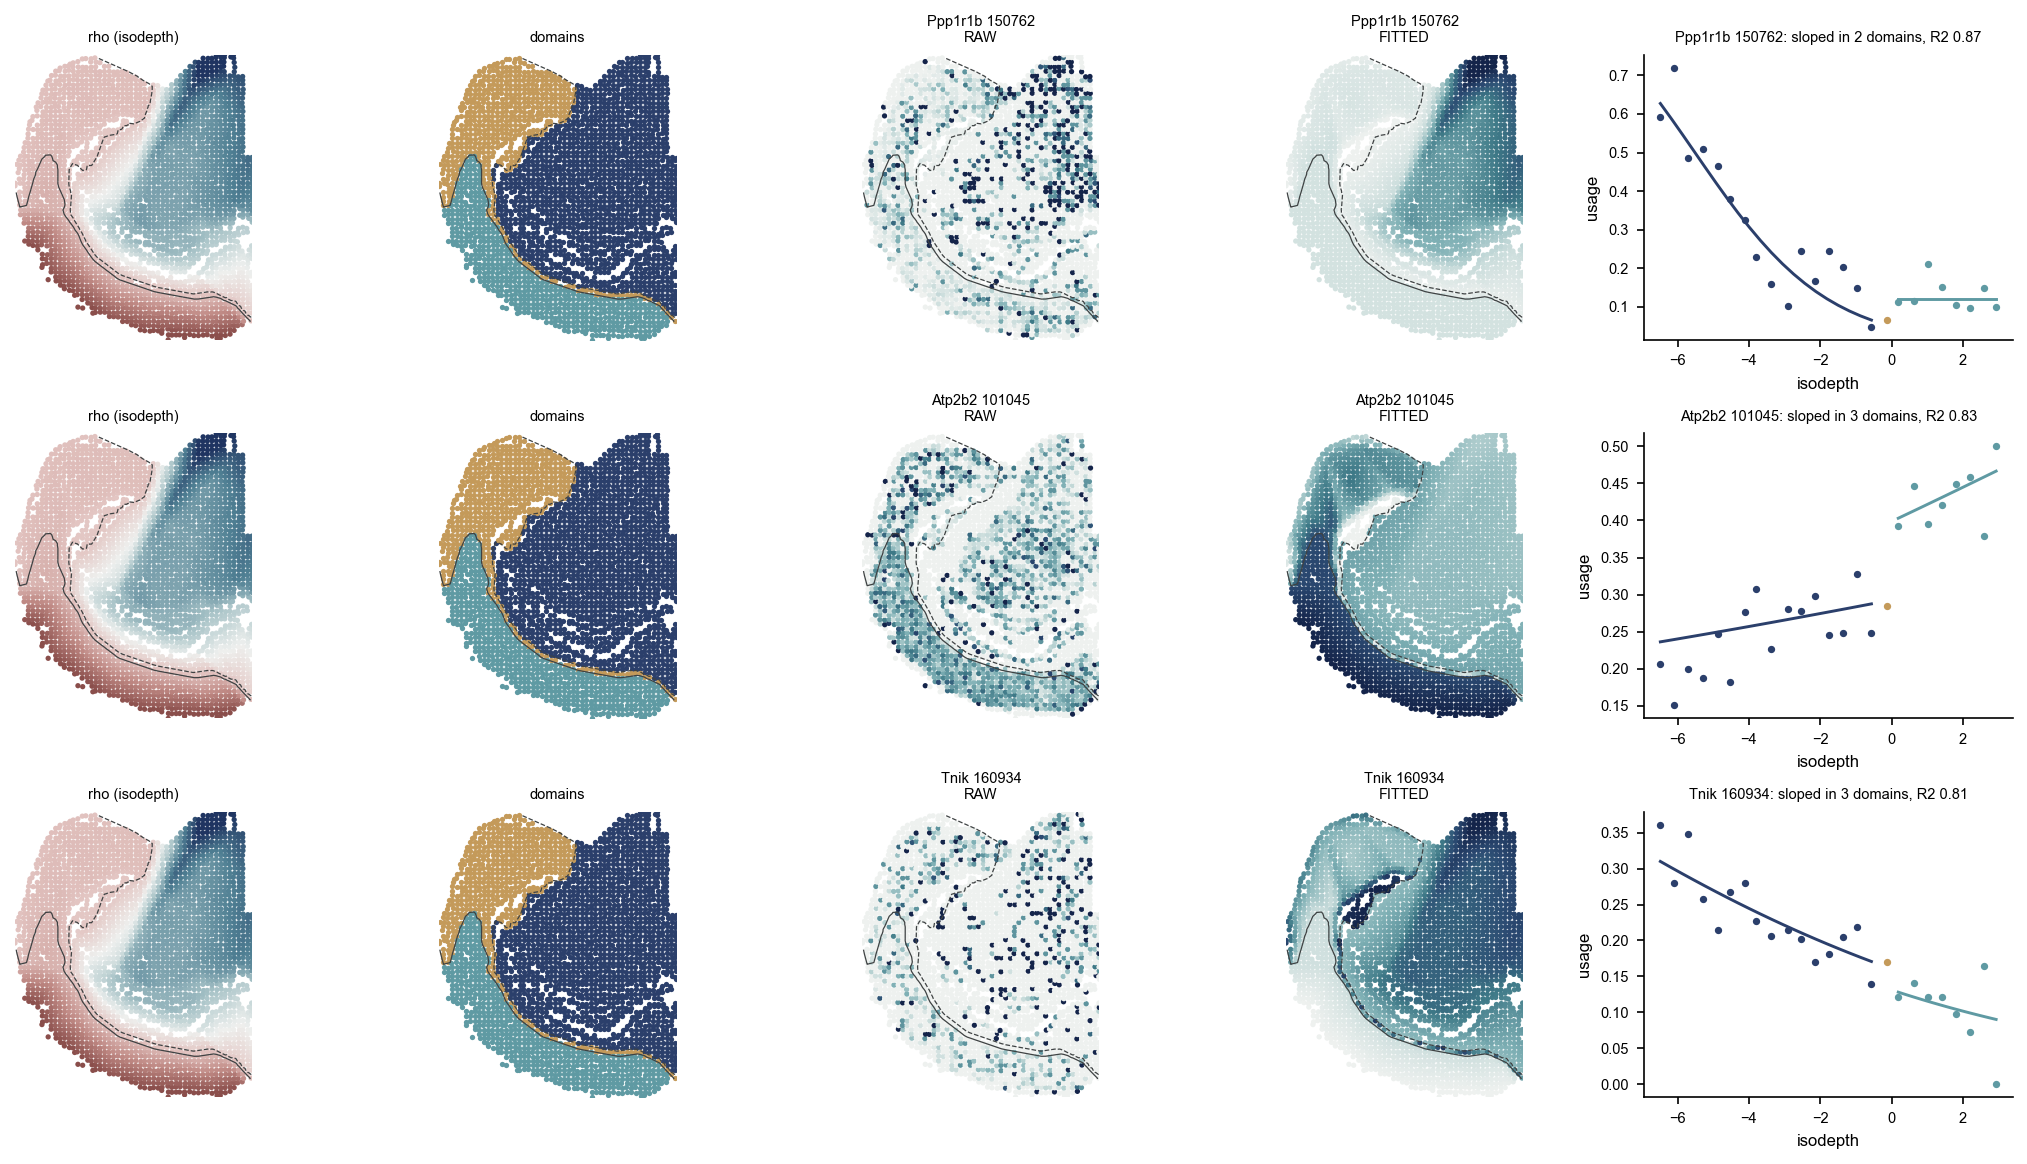

In [17]:
idx = top.index[:3]
fig, AX = plt.subplots(len(idx), 5, figsize=(14, 2.6 * len(idx)), squeeze=False)
for r, j in enumerate(idx):
    saturn.plotting.function_row(AX[r], coords, d_I, lab_I, A[:, j], slope[j], inter[j], pair_label[j], bnd_I, lib=N[:, j], link="logit", unit="usage")
fig.tight_layout(); plt.show()

### Usage that changes while expression stays flat

The published table `domain_slopes.csv` uses a stricter gate than `fit_binomial`. Bins of one gene are over-dispersed, so the
likelihood ratio is divided by the Pearson dispersion of the sloped fit (a quasi-likelihood test), and p values are BH-adjusted in
each domain. The same test is applied to the gene's expression with a Poisson model. A domain then counts an isoform as
`isoform_only` when usage is sloped (q < 0.05 and a usage change of at least 0.15 across the domain) and expression is flat (q >= 0.05
or |log2 fold change| < 0.5). The package has no function for this, so we write the batched fit out.

In [18]:
def glm(A, N, X, fam="binom", off=None, iters=30, ridge=1e-8):
    """batched GLM by IRLS over the columns of A: coefficients, log-likelihood, Pearson statistic per observation"""
    o = np.zeros(len(X)) if off is None else off
    B = np.zeros((A.shape[1], X.shape[1]))
    if fam == "binom":
        p0 = np.clip(A.sum(0) / np.maximum(N.sum(0), 1), 1e-5, 1 - 1e-5); B[:, 0] = np.log(p0 / (1 - p0))
    else:
        B[:, 0] = np.log(np.maximum(A.sum(0), 0.5) / np.exp(o).sum())
    for _ in range(iters):
        eta = X @ B.T + o[:, None]
        if fam == "binom":
            mu = 1 / (1 + np.exp(-np.clip(eta, -30, 30))); W = N * mu * (1 - mu)
            z = eta - o[:, None] + (A - N * mu) / np.maximum(W, 1e-9)
        else:
            mu = np.exp(np.clip(eta, -30, 30)); W = mu
            z = eta - o[:, None] + (A - mu) / np.maximum(mu, 1e-9)
        XtWX = np.einsum("bp,bi,bq->ipq", X, W, X) + ridge * np.eye(X.shape[1])
        B = np.linalg.solve(XtWX, np.einsum("bp,bi->ip", X, W * z)[..., None])[..., 0]
    eta = X @ B.T + o[:, None]
    if fam == "binom":
        mu = np.clip(1 / (1 + np.exp(-np.clip(eta, -30, 30))), 1e-9, 1 - 1e-9)
        ll = (A * np.log(mu) + (N - A) * np.log(1 - mu)).sum(0)
        pr = np.where(N > 0, (A - N * mu) ** 2 / np.maximum(N * mu * (1 - mu), 1e-9), 0)
    else:
        mu = np.exp(np.clip(eta, -30, 30)); ll = (A * np.log(np.maximum(mu, 1e-300)) - mu).sum(0)
        pr = (A - mu) ** 2 / np.maximum(mu, 1e-9)
    return B, ll, pr


def quasi_fit(A, N, x, fam, off=None):
    """one predictor: coefficients and the quasi-likelihood p value of the slope"""
    X = np.c_[np.ones_like(x), x]
    B, ll1, pr = glm(A, N, X, fam, off)
    _, ll0, _ = glm(A, N, X[:, :1], fam, off)
    nobs = (N > 0).sum(0) if fam == "binom" else np.full(A.shape[1], len(x))
    phi = np.maximum(pr.sum(0) / np.maximum(nobs - 2, 1), 1.0)
    return B, chi2.sf(np.maximum(2 * (ll1 - ll0), 0) / phi, 1)


sigmoid = lambda v: 1 / (1 + np.exp(-v))
gene_col = pd.Index(genes).get_indexer(pair_gene)
on_panel = gene_col >= 0
E = np.zeros_like(A)
E[:, on_panel] = counts_R[:, gene_col[on_panel]].toarray()

tables = []
for k in range(lab_I.max() + 1):
    m = lab_I == k
    x = d_I[m]; lo, hi = np.percentile(x, [2, 98]); xc = x - x.mean()
    bu, pu = quasi_fit(A[m], N[m], xc, "binom")
    be, pe = quasi_fit(E[m], None, xc, "pois", off=np.log(lib_R[m]))
    T = pd.DataFrame(dict(gene=pair_gene, isoform=pair_iso, domain=k, gene_reads=N[m].sum(0), usage=A[m].sum(0) / np.maximum(N[m].sum(0), 1),
                          usage_slope=bu[:, 1], usage_du=sigmoid(bu[:, 0] + bu[:, 1] * (hi - x.mean())) - sigmoid(bu[:, 0] + bu[:, 1] * (lo - x.mean())),
                          usage_p=pu, expr_counts=E[m].sum(0), expr_log2fc=be[:, 1] * (hi - lo) / np.log(2), expr_p=pe, gene_on_panel=on_panel))
    ok = T.gene_reads >= 50
    T["usage_q"] = np.nan; T.loc[ok, "usage_q"] = multipletests(T.usage_p[ok], method="fdr_bh")[1]
    okE = ok & T.gene_on_panel & (T.expr_counts >= 20)
    T["expr_q"] = np.nan; T.loc[okE, "expr_q"] = multipletests(T.expr_p[okE], method="fdr_bh")[1]
    T["usage_sloped"] = (T.usage_q < 0.05) & (T.usage_du.abs() >= 0.15)
    T["expr_flat"] = okE & ((T.expr_q >= 0.05) | (T.expr_log2fc.abs() < 0.5))
    T["isoform_only"] = T.usage_sloped & T.expr_flat
    tables.append(T)
slopes = pd.concat(tables, ignore_index=True)
per_domain = slopes[slopes.gene_reads >= 50].groupby("domain").agg(tested=("isoform", "size"), usage_sloped=("usage_sloped", "sum"),
                                                                   expr_flat=("expr_flat", "sum"), isoform_only=("isoform_only", "sum"))
print(per_domain)
print("published\n", pd.DataFrame(pub_prep["per_domain"]).set_index("domain"))

pub_slopes = pd.read_csv(FIT / "isodepth/domain_slopes.csv")
assert (pub_slopes.isoform.values == slopes.isoform.values).all() and (pub_slopes.domain.values == slopes.domain.values).all()
for c in ("usage_slope", "usage_du", "usage_q", "expr_log2fc", "expr_q"):
    print(f"domain_slopes {c}: max|diff| {maxdiff(slopes[c], pub_slopes[c]):.3g}")

kept_slope = slope.T.ravel()                              # same row order as the table: domain, then isoform
gate = (np.abs(kept_slope) > 1e-9) & (pub_slopes.gene_reads.values >= 50)
print(f"fit_binomial vs the published slope, where its gate kept one with >= 50 gene reads: n {gate.sum()}, max|diff| {maxdiff(kept_slope[gate], pub_slopes.usage_slope[gate]):.3g}")
slopes[slopes.isoform_only].sort_values("usage_du", key=abs, ascending=False).head()[["gene", "isoform", "domain", "gene_reads", "usage", "usage_du", "usage_q", "expr_log2fc", "expr_q"]].round(3)

        tested  usage_sloped  expr_flat  isoform_only
domain                                               
0         1556           287        477            67
1         1514           398        335            61
2         1509            70        705            24
published
         tested  usage_sloped  expr_flat  isoform_only
domain                                               
0         1556           287        477            67
1         1514           398        335            61
2         1509            70        705            24
domain_slopes usage_slope: max|diff| 2.33e-10
domain_slopes usage_du: max|diff| 4.52e-15
domain_slopes usage_q: max|diff| 6.46e-10
domain_slopes expr_log2fc: max|diff| 2.1e-10
domain_slopes expr_q: max|diff| 2.07e-10
fit_binomial vs the published slope, where its gate kept one with >= 50 gene reads: n 2040, max|diff| 7.11e-13


,gene,isoform,domain,gene_reads,usage,usage_du,usage_q,expr_log2fc,expr_q
2775,Slc13a3,ENSMUST00000029208,1,285.0,0.442,-0.860,0.000,-0.572,0.680
2620,Prkx,ENSMUST00000036333,1,70.0,0.300,-0.791,0.001,0.055,0.910
1608,Adamts2,ENSMUST00000040523,1,189.0,0.360,-0.767,0.000,0.271,0.812
2886,Syt2,ENSMUST00000188842,1,95.0,0.295,-0.723,0.014,1.935,0.132
1791,Cct7,ENSMUST00000032078,1,130.0,0.323,-0.707,0.001,0.084,0.550


## Isoform switching between domains

Now we compare the two highest domains of `rho_Isoform`, amygdala / olfactory cortex and cortex, which lie next to each other along
the axis. Per isoform we take the pooled usage on each side, and the usage fitted at the boundary from each side (`jump`). An
isoform switches if both sides have at least 100 gene reads and either the dominant isoform flips (usage on opposite sides of 0.5) or
the usage changes by at least 0.2. The package has no function for this.

In [19]:
ka, kc = lab_I.max() - 1, lab_I.max()
ma, mc = lab_I == ka, lab_I == kc
bnd = (d_I[ma].max() + d_I[mc].min()) / 2
ba, _ = quasi_fit(A[ma], N[ma], d_I[ma] - d_I[ma].mean(), "binom")
bc, _ = quasi_fit(A[mc], N[mc], d_I[mc] - d_I[mc].mean(), "binom")
Ta, Tc = slopes[slopes.domain == ka].reset_index(drop=True), slopes[slopes.domain == kc].reset_index(drop=True)
u_a, u_c = sigmoid(ba[:, 0] + ba[:, 1] * (bnd - d_I[ma].mean())), sigmoid(bc[:, 0] + bc[:, 1] * (bnd - d_I[mc].mean()))
S = pd.DataFrame(dict(gene=pair_gene, isoform=pair_iso, reads_2=N[ma].sum(0), reads_3=N[mc].sum(0), usage_2=Ta.usage, usage_3=Tc.usage,
                      change=Tc.usage - Ta.usage, jump=u_c - u_a,
                      expr_log2fc_23=np.log2((E[mc].sum(0) / lib_R[mc].sum() + 1e-9) / (E[ma].sum(0) / lib_R[ma].sum() + 1e-9))))
enough = (S.reads_2 >= 100) & (S.reads_3 >= 100)
S["flip"] = enough & (np.sign(S.usage_2 - 0.5) != np.sign(S.usage_3 - 0.5))
S["switch"] = enough & (S.flip | (S.change.abs() >= 0.2))
S = S.sort_values("change", key=abs, ascending=False)
print(f"boundary at rho_Isoform {bnd:.3f} (published {pub_prep['boundary_23']:.3f}); {int(enough.sum())} isoforms with >= 100 reads on both sides")
print("switches", int(S.switch.sum()), " published", pub_prep["n_switch"], "; dominant flips", int(S.flip.sum()), " published", pub_prep["n_flip"])
pub_S = pd.read_csv(FIT / "isodepth/switch_23.csv")
print("switch_23: same order", (pub_S.isoform.values == S.isoform.values).all(), " max|diff| change", maxdiff(S.change, pub_S.change), " jump", maxdiff(S.jump, pub_S.jump),
      " expr_log2fc", maxdiff(S.expr_log2fc_23, pub_S.expr_log2fc_23))
S[S.switch].head(8).round(3)

boundary at rho_Isoform 0.034 (published 0.034); 1369 isoforms with >= 100 reads on both sides
switches 92  published 92 ; dominant flips 70  published 70
switch_23: same order True  max|diff| change 9.93129189996722e-17  jump 1.915134717478395e-15  expr_log2fc 4.440892098500626e-16


,gene,isoform,reads_2,reads_3,usage_2,usage_3,change,jump,expr_log2fc_23,flip,switch
37,Ace,ENSMUST00000001964,9591.0,2877.0,0.152,0.785,0.633,-0.074,-4.458,True,True
1452,Ttc21a,ENSMUST00000159128,451.0,165.0,0.322,0.927,0.606,0.007,-3.360,True,True
1177,Scube3,ENSMUST00000132670,420.0,240.0,0.362,0.850,0.488,-0.220,-2.035,True,True
1444,Trpm3,ENSMUST00000099564,801.0,158.0,0.371,0.842,0.471,0.027,0.000,True,True
699,Kcnab3,ENSMUST00000018614,2310.0,5783.0,0.129,0.551,0.422,0.404,2.686,True,True
1472,Ubr1,ENSMUST00000133408,834.0,878.0,0.512,0.140,-0.372,-0.531,0.291,True,True
818,Mef2c,ENSMUST00000198199,1664.0,10342.0,0.093,0.459,0.366,0.267,1.077,False,True
955,Pax3,ENSMUST00000172555,573.0,1051.0,0.721,0.372,-0.349,-0.473,-0.579,True,True


Usage can change between two domains because the cells differ or because the same cell type uses another isoform. A Kitagawa split
divides the change exactly into a composition part and a within-cell-type part, using the single cells of each domain, with a
bootstrap of cells inside each type and domain for the confidence interval. We run it for the top 30 switches, and the
random stream is the same as in the published table.

In [20]:
types, ct_code = np.unique(cell_type, return_inverse=True)
cell_dom = np.where(cell_bin >= 0, lab_I[cell_bin.clip(0)], -1)


def kitagawa(a_, t_, f, c):
    af, nf = np.bincount(ct_code[f], a_[f], len(types)), np.bincount(ct_code[f], t_[f], len(types))
    ac, nc = np.bincount(ct_code[c], a_[c], len(types)), np.bincount(ct_code[c], t_[c], len(types))
    pooled = (af + ac) / np.maximum(nf + nc, 1)
    uf, uc = np.where(nf > 0, af / np.maximum(nf, 1), pooled), np.where(nc > 0, ac / np.maximum(nc, 1), pooled)
    wf, wc = nf / max(nf.sum(), 1), nc / max(nc.sum(), 1)
    return ((wc - wf) * (uc + uf) / 2).sum(), ((wc + wf) / 2 * (uc - uf)).sum()


rng = np.random.default_rng(0)
f_all, c_all = np.where(cell_dom == ka)[0], np.where(cell_dom == kc)[0]
in_f = [v for v in (f_all[ct_code[f_all] == t] for t in range(len(types))) if len(v)]
in_c = [v for v in (c_all[ct_code[c_all] == t] for t in range(len(types))) if len(v)]
split = []
for _, r in S[S.switch].head(30).iterrows():
    cols_g = np.where(iso_gene == r.gene)[0]
    t_ = np.asarray(X_iso[:, cols_g].sum(1)).ravel()
    a_ = X_iso[:, np.where(iso_name == r.isoform)[0][0]].toarray().ravel()
    comp, within = kitagawa(a_, t_, f_all, c_all)
    boot = [kitagawa(a_, t_, np.concatenate([rng.choice(v, len(v)) for v in in_f]), np.concatenate([rng.choice(v, len(v)) for v in in_c]))[1] for _ in range(300)]
    split.append(dict(gene=r.gene, isoform=r.isoform, change=comp + within, composition=comp, within=within, within_ci_lo=np.percentile(boot, 2.5), within_ci_hi=np.percentile(boot, 97.5)))
split = pd.DataFrame(split)
pub_split = split[["isoform"]].merge(pub_S, on="isoform")
for c in ("composition", "within", "within_ci_lo", "within_ci_hi"):
    print(f"switch_23 {c}: max|diff| {maxdiff(split[c], pub_split[c]):.3g}")
print("within-type part differs from 0 in", int(((split.within_ci_lo > 0) | (split.within_ci_hi < 0)).sum()), "of", len(split), "; median within share", round((split.within / split.change).median(), 2))
split.head(8).round(3)

switch_23 composition: max|diff| 1.32e-16
switch_23 within: max|diff| 1.11e-16
switch_23 within_ci_lo: max|diff| 1.11e-16
switch_23 within_ci_hi: max|diff| 1.11e-16
within-type part differs from 0 in 19 of 30 ; median within share 0.47


,gene,isoform,change,composition,within,within_ci_lo,within_ci_hi
0,Ace,ENSMUST00000001964,0.633,0.526,0.107,-0.008,0.220
1,Ttc21a,ENSMUST00000159128,0.606,0.590,0.015,-0.015,0.046
2,Scube3,ENSMUST00000132670,0.488,0.512,-0.023,-0.095,0.045
3,Trpm3,ENSMUST00000099564,0.471,0.333,0.138,-0.030,0.199
4,Kcnab3,ENSMUST00000018614,0.422,0.233,0.189,0.153,0.232
5,Ubr1,ENSMUST00000133408,-0.372,-0.127,-0.245,-0.304,-0.159
6,Mef2c,ENSMUST00000198199,0.366,0.061,0.305,0.205,0.355
7,Pax3,ENSMUST00000172555,-0.349,-0.026,-0.323,-0.385,-0.236


Usage maps of two switching isoforms, smoothed over the 25 nearest bins by pooling reads.

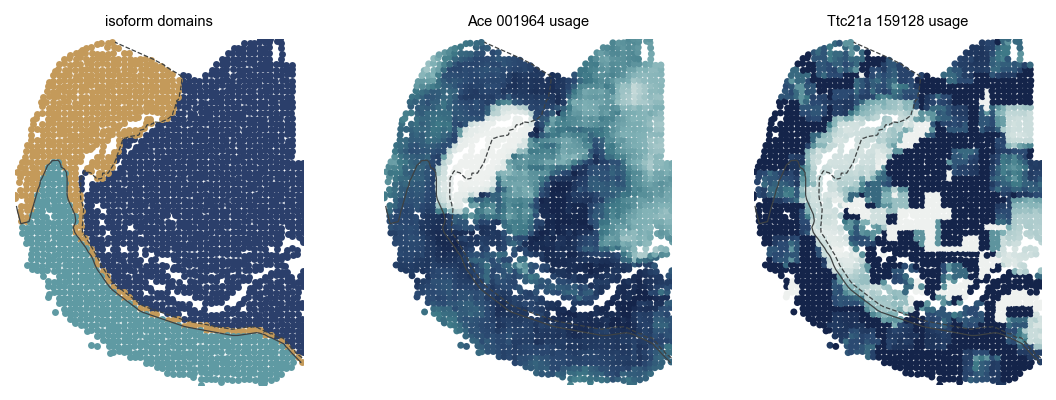

In [21]:
nn = cKDTree(coords).query(coords, k=25)[1]
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
saturn.plotting.spatial(ax[0], coords, lab_I, "isoform domains", discrete=True, contour_d=d_I, bnds=bnd_I)
for a_, (_, r) in zip(ax[1:], split.head(2).iterrows()):
    j = np.where(pair_iso == r.isoform)[0][0]
    saturn.plotting.spatial(a_, coords, A[:, j][nn].sum(1) / np.maximum(N[:, j][nn].sum(1), 1), f"{r.gene} {r.isoform[-6:]} usage", contour_d=d_I, bnds=bnd_I, cmap="saturn_seq_r")
plt.show()

## One cell type across the boundary: Sst interneurons

Sst interneurons sit on both sides of the boundary, so a change of usage inside this type does not come from composition. This
adult section is a spatial continuum of states inside the type, not a time course.

An RNA state score `t` is the cross-validated probability that a cell's expression belongs to the cortex side, from a
logistic regression on a scVI latent space of the Sst cells. scVI runs in another environment (1,000 variable genes, 10 latent
dimensions, seed 42), so we read its saved latent space. Isoforms with at least 80 reads in Sst cells are then tested with a
binomial GLM of usage on `t`, with `t` permuted 500 times across cells as the null, and 500 more times within domains
to ask whether usage follows the RNA state beyond the cell's location. There is no package function for this. The published chain
also runs CellRank 2 for macrostates and a spillover control against neighbouring neurons, which we skip here.

The published score was computed in another environment with scikit-learn 1.8.0, and this kernel has 1.3.2. The score differs by up to
0.00133 (rerunning this logistic regression under 1.8.0 gives the published score to 1e-16). This moves the permutation p values and the
fitted switch points of the isoforms slightly, as the comparison prints, and the counts of switches stay the same.

In [22]:
sel = np.where((cell_type == "Inhibitory_Sst") & (cell_bin >= 0))[0]
Z_sst = np.load(PUB / "rtt_sst_transition/X_scvi.npy")
dom = lab_I[cell_bin[sel]]
pair_side = np.isin(dom, [ka, kc])
y = (dom[pair_side] == kc).astype(int)
clf = LogisticRegression(C=1.0, max_iter=2000)
t = np.zeros(len(sel))
t[pair_side] = cross_val_predict(clf, Z_sst[pair_side], y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
t[~pair_side] = clf.fit(Z_sst[pair_side], y).predict_proba(Z_sst[~pair_side])[:, 1]

pub_states = pd.read_csv(PUB / "rtt_sst_transition/sst_states.csv", index_col=0)
pub_cr = json.load(open(PUB / "rtt_sst_transition/cellrank_summary.json"))
print(len(sel), "Sst cells per domain", np.bincount(dom).tolist(), f" cross-validated AUC {roc_auc_score(y, t[pair_side]):.3f} (published {pub_cr['cv_auc_2v3']})")
print(f"t vs rho_Isoform, Spearman {spearmanr(t, d_I[cell_bin[sel]]).statistic:.3f} (published {pub_cr['t_vs_rho']}); max|diff| t to the published score {maxdiff(t, pub_states.t_state):.3g}")

594 Sst cells per domain [100, 200, 294]  cross-validated AUC 0.925 (published 0.925)
t vs rho_Isoform, Spearman 0.476 (published 0.476); max|diff| t to the published score 0.00133


In [23]:
Xi_sst = X_iso[sel].tocsc()
tot_sst = np.asarray(Xi_sst.sum(0)).ravel()
rows = []
for g, idx in pd.Series(np.arange(len(iso_gene))).groupby(iso_gene):
    if g not in sv_genes:
        continue
    idx = idx.values
    idx = idx[np.argsort(-tot_sst[idx])]
    if tot_sst[idx].sum() < 150:
        continue
    rows += [(g, iso_name[j], j, idx) for j in idx[1:] if tot_sst[j] >= 80 and tot_sst[j] / tot_sst[idx].sum() >= 0.05]
As = np.column_stack([Xi_sst[:, j].toarray().ravel() for _, _, j, _ in rows]).astype(float)
Ns = np.column_stack([np.asarray(Xi_sst[:, ix].sum(1)).ravel() for *_, ix in rows]).astype(float)

one = np.ones(len(t)); tz = (t - t.mean()) / t.std()
fit_b = lambda X_: glm(As, Ns, X_, iters=25, ridge=1e-6)
b, ll1, _ = fit_b(np.c_[one, tz])
_, ll0, _ = fit_b(one[:, None])
rng = np.random.default_rng(42)
null = np.array([fit_b(np.c_[one, rng.permutation(tz)])[0][:, 1] for _ in range(500)])
Dm = np.c_[[(dom == k).astype(float) for k in sorted(set(dom))[1:]]].T
bw, *_ = fit_b(np.c_[one, tz, Dm])
null_w = []
for _ in range(500):
    tp = tz.copy()
    for k in set(dom):
        ii = np.where(dom == k)[0]; tp[ii] = rng.permutation(tz[ii])
    null_w.append(fit_b(np.c_[one, tp, Dm])[0][:, 1])
null_w = np.array(null_w)


def sigmoid4(a_, n_, t_, w=10):
    """4-parameter sigmoid of usage in 10 quantile windows of t, binomial ML: low, high, steepness, switch point t0"""
    q = np.quantile(t_, np.linspace(0, 1, w + 1)); bi = np.clip(np.digitize(t_, q[1:-1]), 0, w - 1)
    tw = np.array([t_[bi == k].mean() for k in range(w)]); aw = np.array([a_[bi == k].sum() for k in range(w)]); nw = np.array([n_[bi == k].sum() for k in range(w)])
    uw = aw / np.maximum(nw, 1)
    def nll(p):
        lo, hi = sigmoid(p[0]), sigmoid(p[1]); u = np.clip(lo + (hi - lo) / (1 + np.exp(-np.exp(p[2]) * (tw - p[3]))), 1e-6, 1 - 1e-6)
        return -(aw * np.log(u) + (nw - aw) * np.log(1 - u)).sum()
    start = [np.log((uw[0] + .02) / (1.02 - uw[0])), np.log((uw[-1] + .02) / (1.02 - uw[-1])), np.log(8)]
    best = min((minimize(nll, start + [t0], method="Nelder-Mead", options=dict(maxiter=4000, xatol=1e-5, fatol=1e-7)) for t0 in (0.25, 0.5, 0.75)), key=lambda r: r.fun)
    return sigmoid(best.x[0]), sigmoid(best.x[1]), float(np.clip(best.x[3], -0.2, 1.2))


Tsst = pd.DataFrame(dict(gene=[r[0] for r in rows], isoform=[r[1] for r in rows], reads=As.sum(0), usage=As.sum(0) / Ns.sum(0), slope_per_sd=b[:, 1], dev_expl=1 - ll1 / ll0,
                         p_perm=((np.abs(null) >= np.abs(b[:, 1])).sum(0) + 1) / 501, p_within_dom=((np.abs(null_w) >= np.abs(bw[:, 1])).sum(0) + 1) / 501))
Tsst["q"] = multipletests(Tsst.p_perm, method="fdr_bh")[1]
Tsst["q_within_dom"] = multipletests(Tsst.p_within_dom, method="fdr_bh")[1]
sg = np.array([sigmoid4(As[:, i], Ns[:, i], t) for i in range(As.shape[1])])
Tsst["du"], Tsst["t0"] = sg[:, 1] - sg[:, 0], sg[:, 2]
Tsst["switch"] = (Tsst.q < 0.1) & (Tsst.du.abs() >= 0.15)
Tsst["state_coupled"] = Tsst.switch & (Tsst.q_within_dom < 0.1)
Tsst = Tsst.sort_values("q")

pub_dyn = pd.read_csv(PUB / "rtt_sst_transition/isoform_dynamics.csv").set_index("isoform").loc[Tsst.isoform]
pub_sum = json.load(open(PUB / "rtt_sst_transition/dynamics_summary.json"))
print(f"{len(Tsst)} isoforms (published {pub_sum['n_tested']}); q < 0.1: {(Tsst.q < 0.1).sum()} ({pub_sum['n_q01']}); switches: {Tsst.switch.sum()} ({pub_sum['n_switch']}); state coupled: {Tsst.state_coupled.sum()} ({pub_sum['n_state_coupled_within_domain']})")
for c in ("slope_per_sd", "dev_expl", "p_perm", "q", "p_within_dom", "du", "t0"):
    print(f"isoform_dynamics {c}: max|diff| {maxdiff(Tsst[c], pub_dyn[c]):.3g}")
Tsst[Tsst.switch].round(3)

26 isoforms (published 26); q < 0.1: 3 (3); switches: 3 (3); state coupled: 1 (1)
isoform_dynamics slope_per_sd: max|diff| 0.000203
isoform_dynamics dev_expl: max|diff| 1.48e-05
isoform_dynamics p_perm: max|diff| 0.00399
isoform_dynamics q: max|diff| 0.00399
isoform_dynamics p_within_dom: max|diff| 0.00399
isoform_dynamics du: max|diff| 0.00132
isoform_dynamics t0: max|diff| 0.0915


,gene,isoform,reads,usage,slope_per_sd,dev_expl,p_perm,p_within_dom,q,q_within_dom,du,t0,switch,state_coupled
11,Kcnab3,ENSMUST00000142328,148.0,0.471,-0.765,0.095,0.002,0.002,0.026,0.052,-0.419,0.815,True,True
24,Vbp1,ENSMUST00000033540,80.0,0.497,0.710,0.086,0.002,0.108,0.026,0.374,0.424,0.767,True,False
6,Coq8b,ENSMUST00000003860,156.0,0.359,0.322,0.019,0.004,0.431,0.035,0.701,0.193,0.844,True,False


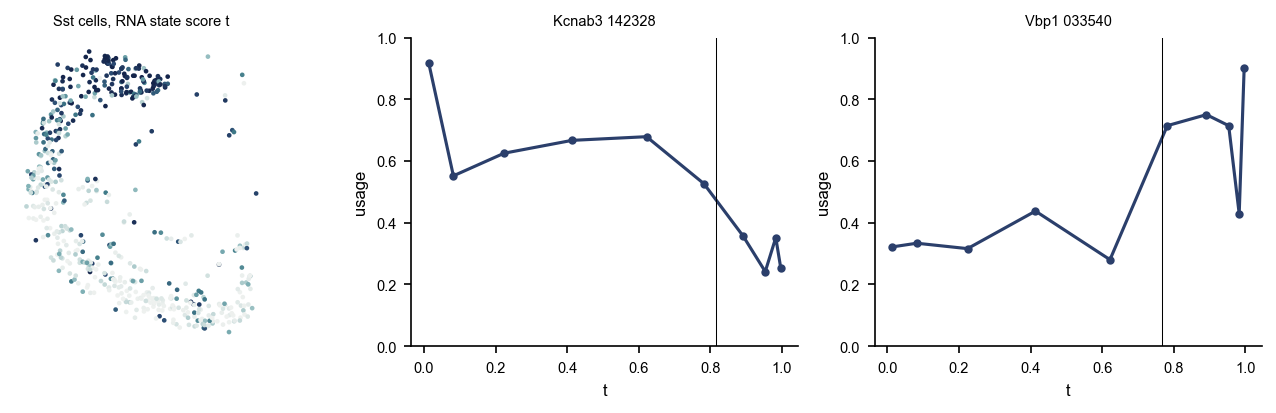

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(9, 2.8))
ax[0].scatter(*cell_xy[sel].T, c=t, s=5, cmap="saturn_seq", lw=0); ax[0].set_aspect("equal"); ax[0].axis("off"); ax[0].set_title("Sst cells, RNA state score t", fontsize=7)
for a_, (_, r) in zip(ax[1:], Tsst[Tsst.switch].head(2).iterrows()):
    i = [k for k, row in enumerate(rows) if row[1] == r.isoform][0]
    q = np.quantile(t, np.linspace(0, 1, 11)); bi = np.clip(np.digitize(t, q[1:-1]), 0, 9)
    a_.plot([t[bi == k].mean() for k in range(10)], [As[bi == k, i].sum() / max(Ns[bi == k, i].sum(), 1) for k in range(10)], "o-", ms=3)
    a_.axvline(r.t0, c="k", lw=.5); a_.set(xlabel="t", ylabel="usage", ylim=(0, 1)); a_.set_title(f"{r.gene} {r.isoform[-6:]}", fontsize=7)
plt.tight_layout(); plt.show()

## Own axis or the other axis

Does an isoform follow its own axis better than the RNA axis? First a binomial model per isoform, with log depth as a covariate:
`usage ~ rho_Isoform` against `usage ~ rho_RNA`, compared by the deviance they explain. This is the published screen.

In [25]:
zs = lambda v: (v - v.mean(0)) / v.std(0)
ri, rr, ld = zs(d_I), zs(d_R), zs(np.log(depth_I.clip(1)))
one = np.ones(len(ri))
fit_s = lambda X_: glm(A, N, X_, iters=25, ridge=1e-6)
b_i, ll_i, _ = fit_s(np.c_[one, ri, ld])
b_r, ll_r, _ = fit_s(np.c_[one, rr, ld])
_, ll_0, _ = fit_s(np.c_[one, ld])
scr = pd.DataFrame(dict(gene=pair_gene, isoform=pair_iso, reads=A.sum(0), slope_iso=b_i[:, 1], slope_rna=b_r[:, 1], dev_expl_iso=1 - ll_i / ll_0, dev_expl_rna=1 - ll_r / ll_0))
pub_scr = pd.read_csv(FIT / "isodepth/usage_screen.csv").set_index("isoform").loc[scr.isoform]
pub_sum2 = json.load(open(FIT / "isodepth/summary.json"))
print(f"rho_Isoform explains more deviance than rho_RNA for {(scr.dev_expl_iso > scr.dev_expl_rna).mean():.3f} of {len(scr)} isoforms (published {pub_sum2['screen']['iso_better_than_rna']})")
for c in ("slope_iso", "slope_rna", "dev_expl_iso", "dev_expl_rna"):
    print(f"usage_screen {c}: max|diff| {maxdiff(scr[c], pub_scr[c]):.3g}")
print("from the published table, with slopes calibrated by 200 rotations of rho_Isoform: isoforms at FDR < 0.05 along rho_Isoform", int((pub_scr.padj_iso < 0.05).sum()), ", beyond rho_RNA", int((pub_scr.padj_iso_given_rna < 0.05).sum()))
scr.sort_values("dev_expl_iso", ascending=False).head().round(4)

rho_Isoform explains more deviance than rho_RNA for 0.565 of 1558 isoforms (published 0.565)
usage_screen slope_iso: max|diff| 1.57e-14
usage_screen slope_rna: max|diff| 5.6e-14
usage_screen dev_expl_iso: max|diff| 1.2e-15
usage_screen dev_expl_rna: max|diff| 1.32e-15
from the published table, with slopes calibrated by 200 rotations of rho_Isoform: isoforms at FDR < 0.05 along rho_Isoform 0 , beyond rho_RNA 0


,gene,isoform,reads,slope_iso,slope_rna,dev_expl_iso,dev_expl_rna
535,Gabre,ENSMUST00000064780,177.0,-2.1137,-3.1250,0.3959,0.3379
224,Ccbe1,ENSMUST00000151343,23.0,-1.5445,-1.4477,0.2015,0.1063
752,Lmo7,ENSMUST00000100337,772.0,-1.0884,-1.4566,0.1843,0.2161
1351,Tcf7l2,ENSMUST00000111651,1339.0,1.4360,1.8171,0.1741,0.1594
1063,Prlr,ENSMUST00000005400,210.0,-1.1261,-2.3174,0.1660,0.1588


No isoform passes when the spatial autocorrelation is taken into account in this whole-section screen, so it ranks by effect size, and
the rest of the analysis tests inside domains. We skip the 200 refits of the rotation null here and read those counts from the table.

`saturn.crossterm.own_vs_cross` asks the same question per feature in variance terms, with a piecewise fit along each axis:
what only the own axis carries (`unique_own`), what only the other axis carries (`unique_cross`), and what they share. It needs
smoothed, z-scored values. `saturn.cis.smoothed_logcpm` gives these for genes, and we pool reads over 15 neighbours for usage. The
manuscript has no such table for this dataset, so there is nothing to compare with.

              genes, own = rho_RNA  isoforms, own = rho_Isoform
R2_own                       0.374                        0.064
R2_cross                     0.350                        0.081
R2_joint                     0.434                        0.096
unique_own                   0.066                        0.011
unique_cross                 0.050                        0.023
shared                       0.291                        0.052
features 1500 1151 ; own axis larger: 0.604 0.309


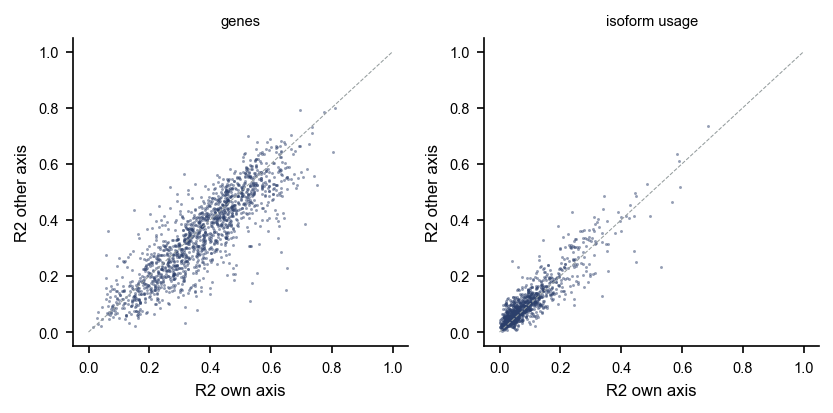

In [26]:
top_genes = np.argsort(-np.asarray(counts_R.sum(0)).ravel().astype(float))[:1500]
Y_genes = saturn.cis.smoothed_logcpm(counts_R, top_genes, coords, k=15)
ovc_R = CT.own_vs_cross(Y_genes, d_R, lab_R, d_I, lab_I)

nn15 = cKDTree(coords).query(coords, k=15)[1]
well = np.where(A.sum(0) >= 200)[0]
U_smooth = A[:, well][nn15].sum(1) / np.maximum(N[:, well][nn15].sum(1), 1)
ovc_I = CT.own_vs_cross(zs(U_smooth), d_I, lab_I, d_R, lab_R)
print(pd.DataFrame({"genes, own = rho_RNA": ovc_R.median(), "isoforms, own = rho_Isoform": ovc_I.median()}).loc[["R2_own", "R2_cross", "R2_joint", "unique_own", "unique_cross", "shared"]].round(3))
print("features", len(ovc_R), len(ovc_I), "; own axis larger:", round((ovc_R.R2_own > ovc_R.R2_cross).mean(), 3), round((ovc_I.R2_own > ovc_I.R2_cross).mean(), 3))

fig, ax = plt.subplots(1, 2, figsize=(5.6, 2.8))
for a_, T, nm in ((ax[0], ovc_R, "genes"), (ax[1], ovc_I, "isoform usage")):
    a_.scatter(T.R2_own, T.R2_cross, s=2, lw=0, alpha=.5); a_.plot([0, 1], [0, 1], ls="--", c=ANCHOR["stone"], lw=.5); a_.set(xlabel="R2 own axis", ylabel="R2 other axis"); a_.set_title(nm, fontsize=7)
plt.tight_layout(); plt.show()

Most of the explained variance is shared, as expected from axes that correlate at 0.92. Isoforms follow the RNA axis at least as well as
their own in this comparison (own axis larger for 0.309 of them), while the deviance screen above favoured `rho_Isoform` for 0.565.
The two differ in model: here each axis is fitted piecewise, and the RNA axis has one more domain, which may favour it.

## What the cross pathways explain

`saturn.crossterm.spot_decomposition` splits the model at each bin. `gain_RNA` is the local gain from the isoform axis: the
drop in error when the cross term may vary, averaged over the 25 nearest bins. `gain_X` is the same for the RNA axis explaining the
isoform target. The published table comes from the same model, with its axes in the same orientation.

merfish_spots rho_RNA: max|diff| 2.29e-07
merfish_spots rho_X: max|diff| 2.38e-07
merfish_spots grad_RNA: max|diff| 4.6e-10
merfish_spots grad_X: max|diff| 2.31e-10
merfish_spots gain_RNA: max|diff| 9.89e-17
merfish_spots gain_X: max|diff| 9.97e-17
R2 RNA {'full': 0.576569711271218, 'own_only': 0.48805107075322063}  R2 isoform {'full': 0.48648685014531756, 'own_only': 0.4565512711560439}


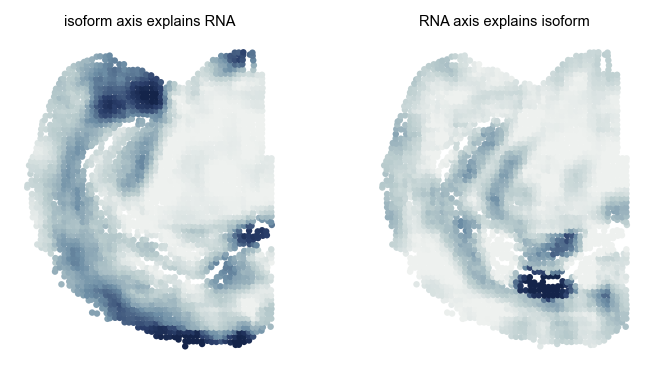

In [27]:
signs = [np.sign(np.corrcoef(res.axes[:, k], pub_axes[f"d_{m}"])[0, 1]) for k, m in enumerate(modalities)]
T, Ssum = CT.spot_decomposition(res.model, coords_z, coords, targets, 0, 1, signs)
T.index = barcodes
pub_T = pd.read_csv(PUB / "saturn_cross_term/merfish_spots.csv", index_col=0)
pub_T.index = pub_T.index.astype(str)
for c in ("rho_RNA", "rho_X", "grad_RNA", "grad_X", "gain_RNA", "gain_X"):
    print(f"merfish_spots {c}: max|diff| {maxdiff(T[c], pub_T.loc[barcodes, c]):.3g}")
print("R2 RNA", Ssum["R2_RNA"], " R2 isoform", Ssum["R2_X"])

fig, ax = plt.subplots(1, 2, figsize=(5.6, 2.8))
saturn.plotting.spatial(ax[0], coords, T.gain_RNA.clip(0, None), "isoform axis explains RNA", cmap="saturn_mono", vmin=0)
saturn.plotting.spatial(ax[1], coords, T.gain_X.clip(0, None), "RNA axis explains isoform", cmap="saturn_mono", vmin=0)
plt.show()

`gene_cross_test` compares `log1p CPM ~ B(rho_RNA)` with `~ B(rho_RNA) + B(rho_Isoform)` for every gene detected in at least 5% of
bins, where `B` is a linear term plus hinges. It returns the gain in variance explained, a partial F test and a Benjamini-Hochberg
q value, and the cross profile of each gene. The F test treats bins as independent although neighbouring bins are correlated, so a
large share of genes passes. Use `dR2_cross` to rank them, and add a minimum effect as below.

In [28]:
Gtab, prof, tested = CT.gene_cross_test(counts_R, genes, T.rho_RNA.values, T.rho_X.values)
pub_G = pd.read_csv(PUB / "saturn_cross_term/merfish_genes.csv")
pub_ct = json.load(open(PUB / "saturn_cross_term/merfish_summary.json"))
print(f"{len(Gtab)} genes tested, {(Gtab.q < 0.05).sum()} with q < 0.05; published table {pub_ct['n_genes']} and {pub_ct['n_cross_fdr05']}")
print("q < 0.05 and dR2_cross >= 0.01:", int(((Gtab.q < 0.05) & (Gtab.dR2_cross >= 0.01)).sum()))
Gtab.head()

13374 genes tested, 8981 with q < 0.05; published table 13374 and 8981
q < 0.05 and dR2_cross >= 0.01: 5252


,gene,detect,R2_own,R2_own_plus_X,dR2_cross,p,q,cross_sd,cross_r_rhoX
2441,Irs4,0.078648,0.344079,0.550184,0.206106,1.414427e-217,1.891654e-213,0.167617,-0.146315
8054,Gm11808,1.000000,0.301159,0.477841,0.176682,2.438833e-167,1.630847e-163,0.405652,-0.252082
11687,Syt2,0.345094,0.116109,0.288024,0.171915,2.281173e-123,7.627100e-120,0.902348,0.882523
12232,Cdh12,0.402058,0.151553,0.304578,0.153025,3.350308e-113,7.467836e-110,0.280786,0.749326
13120,Hpcal1,0.496509,0.155988,0.304350,0.148362,5.983048e-110,8.890810e-107,0.287917,-0.188894


These numbers differ from the published table, and the next cell shows why. The lab script `saturn_cross_term.py` loads the MERFISH
gene counts with `load_rtt_merfish(5)`, whose default is 50 um bins, and looks them up with the barcodes of this fit, which are
100 um bin codes. A code is `x * 1,000,000 + y` in bin units, so the same code points to another place on the 50 um grid, and codes
with no 50 um bin fall on the last row. Repeating that lookup reproduces the published table exactly. The test above uses the correct
100 um counts of the fit, so the published gene table for this dataset should be read with this in mind.

In [29]:
key50 = np.floor(cell_xy / 50.0).astype(np.int64)
code50 = key50[:, 0] * 1_000_000 + key50[:, 1]
u50, inv50, c50 = np.unique(code50, return_inverse=True, return_counts=True)
k50 = np.where(c50 >= 3)[0]
G50 = sp.csr_matrix((np.ones(len(inv50)), (inv50, np.arange(len(inv50)))), shape=(len(u50), len(inv50)))[k50]
lookup = pd.Index(u50[k50].astype(str)).get_indexer(pd.Index(barcodes))
print("100 um barcodes with no 50 um bin:", int((lookup < 0).sum()), "of", len(barcodes))
G_as_pub, *_ = CT.gene_cross_test(sp.csr_matrix(G50 @ X_gene)[lookup], genes, T.rho_RNA.values, T.rho_X.values)
print(f"with the 50 um lookup: {len(G_as_pub)} genes, {(G_as_pub.q < 0.05).sum()} with q < 0.05; max|diff| dR2_cross to the published table",
      maxdiff(G_as_pub.set_index("gene").dR2_cross.reindex(pub_G.gene), pub_G.dR2_cross))
both = Gtab.merge(pub_G, on="gene", suffixes=("", "_pub"))
print(f"correct bins vs the published table, {len(both)} shared genes: Pearson r of dR2_cross {both.dR2_cross.corr(both.dR2_cross_pub):.3f}")
print(both[both.gene.isin(["Calb2", "Syt2", "Tcf7l2"])][["gene", "dR2_cross", "q", "dR2_cross_pub", "q_pub"]].round(4))

100 um barcodes with no 50 um bin: 531 of 2721


with the 50 um lookup: 8487 genes, 2419 with q < 0.05; max|diff| dR2_cross to the published table 0.14581615098568465
correct bins vs the published table, 13374 shared genes: Pearson r of dR2_cross 1.000
        gene  dR2_cross    q  dR2_cross_pub  q_pub
2       Syt2     0.1719  0.0         0.1719    0.0
614   Tcf7l2     0.0390  0.0         0.0390    0.0
2047   Calb2     0.0210  0.0         0.0210    0.0


The genes that gain most, drawn as the expression map, the isoform axis and the cross profile of the gene.

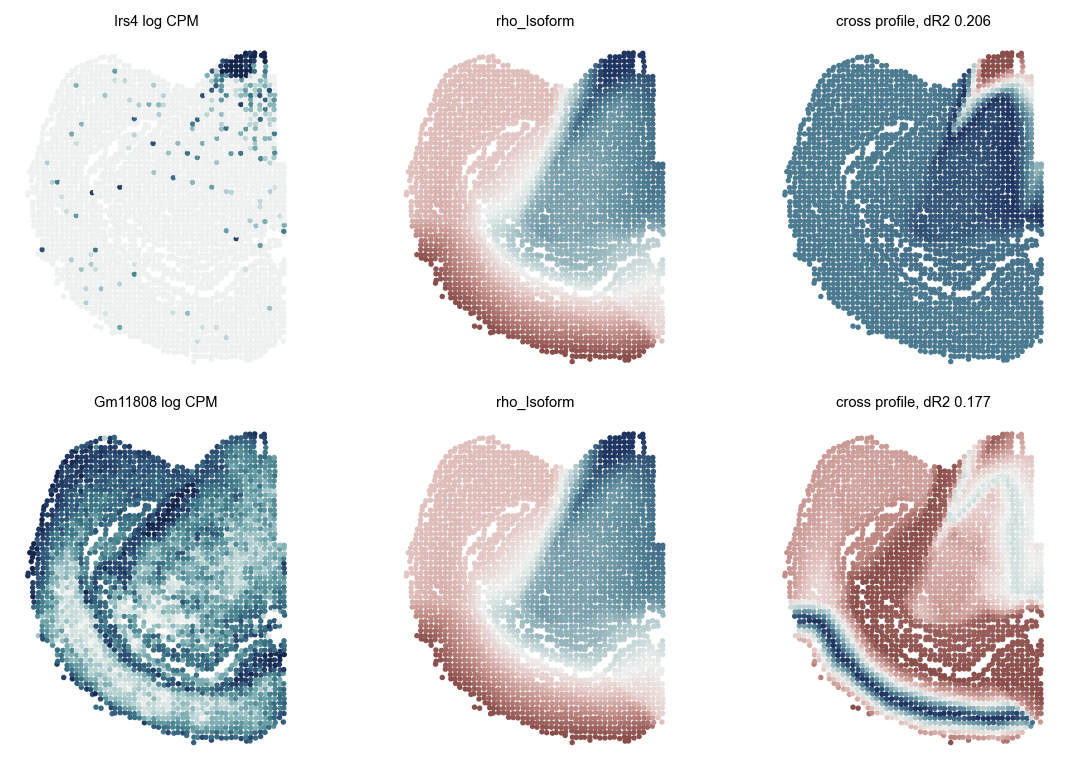

In [30]:
L = CT.logcpm(counts_R, np.isin(genes, tested))
fig, ax = plt.subplots(2, 3, figsize=(8, 5.2))
for r, (i, row) in enumerate(Gtab.head(2).iterrows()):
    saturn.plotting.spatial(ax[r, 0], coords, L[:, i], f"{row.gene} log CPM", cmap="saturn_seq_r")
    saturn.plotting.spatial(ax[r, 1], coords, T.rho_X, "rho_Isoform")
    saturn.plotting.spatial(ax[r, 2], coords, prof[:, i], f"cross profile, dR2 {row.dR2_cross:.3f}")
plt.tight_layout(); plt.show()

`steepness_test` asks whether the gain follows the places where one axis changes faster than the other, against rotations of the
gain map. `depth` adds a depth-partial correlation. Here the RNA gain is lower where the isoform axis is steeper (rho -0.516, rotation
p 0.0199), and the isoform gain shows no trend (rho -0.058, p 0.587). This test uses only the model, so it agrees with the published table.

In [31]:
T["depth"] = depth_R
st = CT.steepness_test(T, nrot=200)
print(json.dumps(st, indent=1))
print("published", {k: dict(rho=round(pub_ct[k]["rho"], 4), p_rot=round(pub_ct[k]["p_rot"], 4), gain_by_quintile=pub_ct[k]["gain_by_quintile"]) for k in ("steeper_RNA", "steeper_X")})

{
 "steeper_RNA": {
  "rho": -0.5159270301788537,
  "p_rot": 0.01990049751243781,
  "null_sd": 0.23143610087752964,
  "gain_by_quintile": [
   0.1408,
   0.1073,
   0.0786,
   0.0824,
   0.0293
  ],
  "rho_depth_partial": -0.5241836579191137
 },
 "steeper_X": {
  "rho": -0.057911505622016135,
  "p_rot": 0.5870646766169154,
  "null_sd": 0.13650977552555174,
  "gain_by_quintile": [
   0.0255,
   0.0483,
   0.0287,
   0.0224,
   0.0255
  ],
  "rho_depth_partial": -0.06407780099354506
 }
}
published {'steeper_RNA': {'rho': -0.5159, 'p_rot': 0.0199, 'gain_by_quintile': [0.1408, 0.1073, 0.0786, 0.0824, 0.0293]}, 'steeper_X': {'rho': -0.0579, 'p_rot': 0.5871, 'gain_by_quintile': [0.0255, 0.0483, 0.0287, 0.0224, 0.0255]}}


## Saving the result

`save` writes the model weights, the axes and the summary. `load_model` reads the weights back for later analyses.

In [32]:
res.save("outputs/tutorial_merfish_isoform", coords=coords, barcodes=barcodes)
model = saturn.load_model("outputs/tutorial_merfish_isoform/saturn_best.pt", [Y_R.shape[1], Y_I.shape[1]])
print(np.abs(saturn.decompose(model, coords_z)[0] - res.axes).max())

0.0
